In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc
import pingouin as ping
import hyppo as hyp

In [59]:
def print_mat(a):
    n = len(a)
    for i in range(n):
        for j in range(n):
            print (a[i][j], end = " ")
        print("\n")
    print("\n")   
        
def power(a, print_mat):
    for k in range(11,21):
        print_mat(np.linalg.matrix_power(a, k))

def stationary_d(a):
    s = -1
    vals, vect = sc.linalg.eig(a, left = True, right = False)
    for k in range (len(vals)):
        if np.abs(vals[k]- 1) <= 1/1000:
            s = k
    print(vect[:, s] / np.sum(vect[:, s]))
            
a1 = [ [1/4, 3/4, 0, 0], [1/2, 0, 1/2, 0], [0, 1/2, 0, 1/2], [0, 0, 3/4, 1/4] ]
a2 = [ [2/9, 1/3, 0, 4/9], [4/9, 1/9, 0, 4/9], [2/9, 2/9, 2/9, 1/3], [2/9, 2/9, 4/9, 1/9] ]
a3 = [ [0, 1/2, 0, 1/2], [1/3, 0, 2/3, 0], [0, 1/4, 0, 3/4], [1/4, 0, 3/4, 0] ]
a4 = [ [1/6, 1/6, 1/6, 1/2, 0], [0, 1/3, 0, 2/3, 0], [0, 0, 0, 0, 1], [0, 1, 0, 0, 0], [0, 0, 1, 0, 0] ]
for a in [a1, a2, a3, a4]:
    stationary_d(a)
    power(a, print_mat)

[0.2 0.3 0.3 0.2]
0.18294835090637207 0.34076714515686035 0.2592329978942871 0.21705150604248047 

0.22717809677124023 0.24218130111694336 0.357818603515625 0.1728219985961914 

0.1728219985961914 0.357818603515625 0.24218130111694336 0.22717809677124023 

0.21705150604248047 0.2592329978942871 0.34076714515686035 0.18294835090637207 



0.2161206603050232 0.2668277621269226 0.3331722021102905 0.18387937545776367 

0.17788517475128174 0.3492928743362427 0.25070714950561523 0.22211480140686035 

0.22211480140686035 0.25070714950561523 0.3492928743362427 0.17788517475128174 

0.18387937545776367 0.3331722021102905 0.2668277621269226 0.2161206603050232 



0.1874440461397171 0.32867659628391266 0.27132341265678406 0.21255594491958618 

0.21911773085594177 0.2587674558162689 0.3412325382232666 0.1808822751045227 

0.1808822751045227 0.3412325382232666 0.2587674558162689 0.21911773085594177 

0.21255594491958618 0.27132341265678406 0.32867659628391266 0.1874440461397171 



0.21119930967688

In [ ]:
Найти стационарное распределение. Построить траекторию цепи. Сходится ли она п.н.? Найти долю

посещений каждого из состояний за большое число n шагов. Сходится ли она п.н.? Моделируем 100 тра-
екторий и для каждой вычтем из доли посещения первого состояния соответствующую стационарную

вероянтость, умножим результат на √

n. Построить гистограмму полученного распределения. Сравнить

результаты с известными теоремами для цепей Маркова.

[0.47368421 0.21052632 0.31578947]
доли: [0.4840000000000004, 0.20600000000000016, 0.3100000000000002]
[1 0 0 3 0 0 0 1 0 1 0 1 1 3 1 0 1 1 1 0 1 0 2 0 1 1 0 0 1 1 2 1 1 0 2 1 1
 4 1 1 0 1 3 1 1 2 2 1 1 2 4 0 1 1 1 1 0 2 0 1 1 2 0 1 1 1 2 1 0 1 1 0 1 0
 2 0 0 2 0 2 3 2 2 0 2 0 1 0 0 0 2 1 2 3 0 0 1 1 0 0 0 0 1 1 7 0 0 2 1 3 0
 0 0 0 0 1 3 1 1 1 0 1 0 2 0 0 1 0 1 0 0 0 1 1 1 1 3 0 0 0 3 5 0 4 1 0 2 1
 0 1 1 1 4 0 0 2 3 2 1 2 1 1 1 0 3 1 1 0 0 1 0 1 1 0 2 1 0 0 2 0 4 2 1 3 0
 0 0 0 1 0 1 0 0 1 1 0 1 2 1 0 6 1 0 2 1 0 0 1 2 1 1 1 1 2 0 3 1 3 2 1 1 3
 3 1 0 2 2 1 1 4 3 0 0 3 1 0 1 0 1 0 2]
1.335273153010451


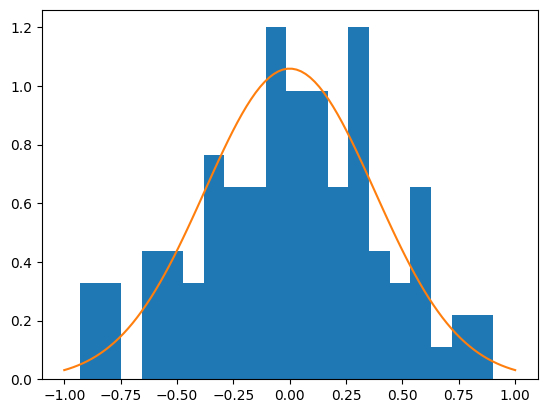

In [37]:
def stationary_d(a):
    s = -1
    vals, vect = sc.linalg.eig(a, left = True, right = False)
    for k in range (len(vals)):
        if np.abs(vals[k]- 1) <= 1/1000:
            s = k
    print(vect[:, s] / np.sum(vect[:, s]))
    return vect[:, s] / np.sum(vect[:, s])
    
def markov_chain(p, n, p_0):
    x = [-1]*n
    s = len(p[0])
    vals = [j for j in range(s)]
    x[0] = int(np.random.choice(vals, p=p_0))
    for k in range(1,n):
        x[k] = int(np.random.choice(vals, p=p[x[k-1]]))
    return x

def share(x, s): #s-число состояний
    nu = [0 for j in range(s)]
    n = len(x)
    for k in range(n):
        nu[x[k]]+=1/n
    return(nu)
    
p = [ [1/3, 1/3, 1/3], [3/4, 0, 1/4], [1/2, 1/6, 1/3] ]
p_0 = [1, 0, 0]
n = 500

stat = stationary_d(p)
x = markov_chain(p, n, p_0)
#print(x)
print("доли:", share(x, 3))

tau = []
time = 0
for k in range(1, n):
    time +=1
    if x[k] == 0:
        tau.append(time)
        time = 0

print(np.array(tau) - 1)
print(np.var( np.array(tau) - 1 ))

N = 100
nu_hat = [0]*N
for j in range(N):
    x = markov_chain(p, n, p_0)
    nu_hat[j] = np.sqrt(n) * (share(x, 3)[0] - stat[0])
plt.hist(nu_hat, density = "True", bins = 20)
l = np.linspace(-1, 1, 100)
plt.plot(l, sc.stats.norm.pdf(l, 0, np.sqrt(np.var(tau)*stat[0]**3) ))
plt.show()

In [ ]:
Какую м.в.п. имеет обращенная цепь ξN−n? Исследовать к какому распределению сходится а) прямая
цепь б) обращенная цепь?

тут есть обратимость в сост равновесия

In [12]:
def stationary_d(a):
    s = -1
    vals, vect = sc.linalg.eig(a, left = True, right = False)
    for k in range (len(vals)):
        if np.abs(vals[k]- 1) <= 1/1000:
            s = k
    return vect[:, s] / np.sum(vect[:, s])

def print_mat(a):
    n = len(a)
    for i in range(n):
        for j in range(n):
            print (a[i][j], end = " ")
        print("\n")
    print("\n")

def power(a, print_mat):
    for k in range(11,20):
        print_mat(np.linalg.matrix_power(a, k))

def markov_chain(p, n, p_0):
    x = [-1]*n
    s = len(p[0])
    vals = [j for j in range(s)]
    x[0] = int(np.random.choice(vals, p=p_0))
    for k in range(1,n):
        x[k] = int(np.random.choice(vals, p=p[x[k-1]]))
    return x

s = 4 # число состояний
p = [ [0, 0, 1/2, 1/2], [0, 0, 0, 1], [1/2, 0, 0, 1/2], [1/3, 1/3, 1/3, 0] ]
pi = stationary_d(p)
print("стац для изначальной", pi)
#power(p, print_mat)

p_rev = [ [0]*s for _ in range(s)]
for i in range (s):
    for j in range (s):
        p_rev[i][j] = p[j][i] * pi[j] / pi[i]
        
print("стац для обращённой", stationary_d(p_rev) )


print_mat(p_rev)
print("\n\n\n")

print("степени обращённой")
power(p_rev, print_mat)

print("\n\n\n")

print("степени прямой")
power(p, print_mat)

стац для изначальной [0.25  0.125 0.25  0.375]
стац для обращённой [0.25  0.125 0.25  0.375]
0.0 0.0 0.5000000000000003 0.49999999999999994 

0.0 0.0 0.0 0.9999999999999998 

0.4999999999999997 0.0 0.0 0.49999999999999967 

0.33333333333333337 0.33333333333333337 0.33333333333333354 0.0 







степени обращённой
0.24791827417695475 0.12190152391975309 0.2484065554269549 0.38177364647633744 

0.24380304783950615 0.114551183127572 0.2438030478395063 0.39784272119341557 

0.2484065554269546 0.12190152391975301 0.24791827417695472 0.3817736464763372 

0.25451576431755835 0.13261424039780523 0.25451576431755846 0.3583542309670782 



0.25146115987225653 0.12725788215877915 0.25121701924725665 0.37006393872170784 

0.2545157643175583 0.1326142403978052 0.2545157643175584 0.3583542309670782 

0.25121701924725637 0.12725788215877906 0.25146115987225653 0.37006393872170756 

0.2467092924811386 0.11945141032235941 0.2467092924811387 0.3871300047153635 



0.24896315586419757 0.12335464624056927

In [ ]:
Моделировать случайное блуждание а) на целочисленной решетке прямой, выбирающее равновероятно
одну из двух соседних точек б) на целочисленной решетке плоскости, выбирающее равновероятно одну
из четырех соседних точек в) в трехмерном пространстве, выбирающее равновероятно одну из шести
соседних точек. Какие из них, исходя из моделирования, оказались возвратными?

In [29]:
def walk_1d(n):
    s = [0]*(n)
    for k in range(1,n):
        s[k]=s[k-1] + int(2*(np.random.binomial(1, 1/2) - 1/2))
    return s
    
def walk_2d(n):
    s = [[0, 0] for _ in range(n)]
    for k in range(1,n):
        ind = int( np.random.choice( [0,1], p=[1/2, 1/2] ) )
        s[k] = [s[k-1][j] for j in range(2)]
        s[k][ind] = s[k-1][ind] + 2*(np.random.binomial(1, 1/2) - 1/2)
    return s
    
def walk_3d(n):
    s = [[0, 0, 0] for _ in range(n)]
    for k in range(1,n):
        ind = int( np.random.choice( [0,1,2], p=[1/3, 1/3, 1/3] ) )
        s[k] = [s[k-1][j] for j in range(3)]
        s[k][ind] = s[k-1][ind] + 2*(np.random.binomial(1, 1/2) - 1/2)
    return s

n = 100 # время блуждания
N = 100 #число блужданий

count1 = 0
for l in range(N):
    walk = walk_1d(n)
    for m in range(1,n):
        if walk[m] == 0:
            count1 += 1/N
            break
print(count1)

n = 100
N = 100
count2 = 0
for l in range(N):
    walk = walk_2d(n)
    for m in range(1,n):
        if walk[m] == [0,0]:
            count2 += 1/N
            break
print(count2)

n = 100
N = 100
count2 = 0
for l in range(N):
    walk = walk_3d(n)
    for m in range(1,n):
        if walk[m] == [0,0,0]:
            count2 += 1/N
            break
print(count2)

0.9600000000000006
0.6300000000000003
0.35000000000000014


In [ ]:
Эренфест
Xn = число белых
изначально N

var: 2N/4 (эргод - бином)
для N = 50 надо 100 000 шагов для норм оценки

In [5]:
def print_mat(a):
    n = len(a)
    for i in range(n):
        for j in range(n):
            print (a[i][j], end = " ")
        print("\n")
    print("\n")

def stationary_d(a):
    s = -1
    vals, vect = sc.linalg.eig(a, left = True, right = False)
    for k in range (len(vals)):
        if np.abs(vals[k]- 1) <= 1/1000:
            s = k
    print("стац распр:", vect[:, s] / np.sum(vect[:, s]))
    return vect[:, s] / np.sum(vect[:, s])

def eren(N, n):
    x = [N]*n
    for k in range(1, n):
        if x[k-1] == 0:
            x[k] = 1
        if x[k-1] == 2*N:
            x[k] = 2*N - 1
        else:
            x[k] = x[k-1] + int(2*(np.random.binomial(1, (2*N - x[k-1])/(2*N)) - 1/2))
    return x

def mle_mark(x, N):
    n = len(x)
    p_hat = [[0]*(2*N+1) for _ in range(2*N+1)]
    for k in range(1,n):
        p_hat[x[k-1]][x[k]] += 1
    for s in range (2*N+1):
        if np.sum(p_hat[s]) > 1/2:
            p_hat[s] = p_hat[s] / np.sum(p_hat[s])
    return p_hat

N = 50
n = 1000

p_true = [[0]*(2*N+1) for _ in range (2*N+1)]
for i in range (1, 2*N):
    p_true[i][i-1] = i/(2*N)
    p_true[i][i+1] = (2*N - i)/(2*N)
p_true[0][1] = 1
p_true[2*N][2*N-1] = 1

#stat = stationary_d(p_true)
x = eren(N, n)
print_mat(p_true)
print_mat( mle_mark(x, N) )
print("оценка дисперсии эргодического распределения:", np.var(x))

0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

0.01 0 0.99 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

0 0.02 0 0.98 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

0 0 0.03 0 0.97 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

0 0 0 0.04 0 0.96 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 

In [5]:
from collections import deque

def read_matrix(filename):
    with open(filename, 'r') as f:
        lines = [line.strip() for line in f if line.strip()]
    p = []
    for line in lines:
        p.append(list(map(float, line.split(";"))))
    return np.array(p)

def markov_chain(p, n, p_0):
    x = [-1]*n
    s = len(p[0])
    vals = list(range(s))
    x[0] = int(np.random.choice(vals, p=p_0))
    for k in range(1, n):
        x[k] = int(np.random.choice(vals, p=p[x[k-1]]))
    return x


p = read_matrix("MarkovChain.txt")
n = len(p[0])

R = np.zeros((n, n), dtype=bool)
for i in range(n):
    for j in range(n):
        if p[i, j] > 0:
            R[i, j] = True

for k in range(n):
    for i in range(n):
        if R[i, k]:
            for j in range(n):
                if R[k, j]:
                    R[i, j] = True


used = [0]*n
classes = []
for i in range(n):
    if used[i] == 0:
        cls = [j for j in range(n) if R[i, j] and R[j, i]]
        for j in cls:
            used[j] = 1
        classes.append(cls)


results = []
for cls in classes:
    s = cls[0]
    dist = {v: -1 for v in cls}
    dist[s] = 0
    q = deque([s])
    while q:
        u = q.popleft()
        for v in cls:
            if p[u, v] > 0 and dist[v] == -1:
                dist[v] = dist[u] + 1
                q.append(v)

    
    g = 0
    for u in cls:
        for v in cls:
            if p[u, v] > 0:
                diff = dist[u] + 1 - dist[v]
                if g == 0:
                    g = abs(diff)
                else:
                    g = np.gcd(g, abs(diff))
    period = g if g != 0 else 1

    subclasses = [[] for _ in range(period)]
    for v in cls:
        r = dist[v] % period
        subclasses[r].append(v)
        
    results.append((cls, period, subclasses))

for i, (cls, period, subcls) in enumerate(results):
    print("класс", i+1,": состояния", cls)
    print(" d =", period)
    print("  циклические подклассы:")
    for r, states in enumerate(subcls):
        print("  подкласс", r,":", states)
    print("\n")


p0 = [1/n]*n
traj = markov_chain(p, 20, p0)
print("Состояние\tКласс\tПодкласс")
info = {}
for cls_idx, (cls, period, subcls) in enumerate(results):
    for r, states in enumerate(subcls):
        for st in states:
            info[st] = (cls_idx, r, period)
for t, st in enumerate(traj):
    cls_idx, r, period = info[st]
    print(f"{st}\t\t{cls_idx}\t{r}")


класс 1 : состояния [0, 37]
 d = 2
  циклические подклассы:
  подкласс 0 : [0]
  подкласс 1 : [37]


класс 2 : состояния [1, 2, 5, 7, 9, 10, 11, 12, 13, 14, 15, 19, 20, 21, 25, 26, 27, 28, 29, 30, 32, 33, 34, 35, 42, 43, 44, 47, 49]
 d = 4
  циклические подклассы:
  подкласс 0 : [1, 14, 26, 28, 30]
  подкласс 1 : [5, 9, 11, 20, 25, 43]
  подкласс 2 : [2, 7, 13, 19, 27, 32, 33, 34, 42]
  подкласс 3 : [10, 12, 15, 21, 29, 35, 44, 47, 49]


класс 3 : состояния [3, 17, 48]
 d = 3
  циклические подклассы:
  подкласс 0 : [3]
  подкласс 1 : [17]
  подкласс 2 : [48]


класс 4 : состояния [4, 16, 18, 22, 41, 46]
 d = 3
  циклические подклассы:
  подкласс 0 : [4]
  подкласс 1 : [16, 46]
  подкласс 2 : [18, 22, 41]


класс 5 : состояния [6, 8, 23, 24, 36, 38, 40, 45]
 d = 2
  циклические подклассы:
  подкласс 0 : [6, 8, 23, 38]
  подкласс 1 : [24, 36, 40, 45]


класс 6 : состояния [31, 39]
 d = 2
  циклические подклассы:
  подкласс 0 : [31]
  подкласс 1 : [39]


Состояние	Класс	Подкласс
41		3	2
4